In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
os.environ["XLA_PYTHON_CLIENT_MEM_FRACTION"] = "0.95"

In [2]:
import matplotlib.pyplot as plt
%matplotlib inline
import jax
import jax.numpy as jnp
import jax.random as jr
import optax
import math

import k3d
import numpy as np
from matplotlib.colors import ListedColormap
from typing import Callable
from functools import partial

from implicitSurfaces.lipschitzImplicit import sdfImplicit
from implicitSurfaces.harmonicImplicit import poissonSurface
from implicitSurfaces.sdf_primitives import sphere_sdf, bbox_sdf, arc2d
from sphereWalker.integrator import WoSIntegrator, DifferentialWoSIntegrator
from sphereWalker.sampling import sample_uniform_1sphere
from utils.losses import volume_integral_loss_grad, surface_integral_loss_grad, l2_loss, dL2_du, surface_integral_loss_grad_normalized
from utils.tree_ops import binary_tree_op, accumulate_weighted_trees
import operator
from utils.helpers import mesh_2d

In [3]:
jax.config.update("jax_debug_nans", True)

In [4]:
def smily_sdf(params, x):
    outer_boundary = bbox_sdf({'min_corner': jnp.array([-1., -1.]), 'max_corner': jnp.array([1., 1.])}, x)
    left_eye = sphere_sdf({'center': jnp.array([-0.5, 0.5]), 'radius': jnp.array(0.2)}, x)
    right_eye = sphere_sdf({'center': jnp.array([0.5, 0.5]), 'radius': jnp.array(0.2)}, x)
    tb = 3.14 * (0.25 + 0.5 * 0.1)
    mouth = arc2d({'sc': jnp.array([jnp.sin(tb), jnp.cos(tb)]), 'ra': jnp.array(0.65), 'rb': jnp.array(0.12)}, -x)
    eyes_and_mouth = jnp.minimum(jnp.minimum(left_eye, right_eye), mouth)
    return jnp.maximum(outer_boundary, -eyes_and_mouth)


In [5]:
bbox_sdf({'min_corner': jnp.array([-1., -1.]), 'max_corner': jnp.array([1., 1.])}, jnp.array([0., 0.]))

Array(-0.999999, dtype=float32)

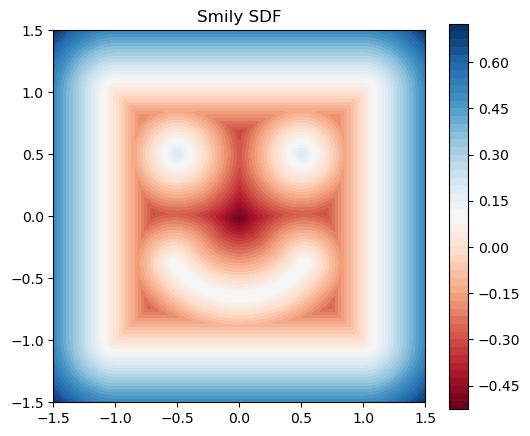

In [6]:
X, Y = mesh_2d(128, ((-1.5, 1.5), (-1.5, 1.5)))
points = jnp.stack([X, Y], axis=-1).reshape(-1, 2)

fig = plt.figure(figsize=(6, 5))
ax = fig.add_subplot(111)
contouf = ax.contourf(X, Y, jax.vmap(smily_sdf)(None, points).reshape(X.shape), levels=50, cmap='RdBu')
ax.set_aspect('equal')
ax.set_title('Smily SDF')
plt.colorbar(contouf)
plt.show()

In [7]:
def sum_of_circles_sdf(params, x):
    dist = jnp.inf
    for circ_param in params:
        dist = jnp.minimum(dist, sphere_sdf(circ_param, x))
    return dist

In [8]:
surface_params = poissonSurface.init_monopole_field(jr.PRNGKey(0), bbox=((-0.5, 0.5), (-0.5, 0.5)), num_points=1)
radii = jnp.ones((surface_params['p'].shape[0],)) * 1.0
to_opt_params = tuple({'center': jnp.array([-0., -0.]), 'radius': radii[i]} for i in range(surface_params['p'].shape[0]))[0]
#outer_boundary = lambda params, x: bbox_sdf({'min_corner': jnp.array([-1., -1.]), 'max_corner': jnp.array([1., 1.])}, x)
outer_boundary = lambda params, x: sphere_sdf({'center': jnp.array([0.0000, 0.0000]), 'radius': jnp.array(1.5)}, x)
#composed_field_fn = lambda p, x: jnp.maximum(-sum_of_circles_sdf(p, x), outer_boundary(p, x))
composed_field_fn = lambda p, x: jnp.maximum(-sphere_sdf(p, x), outer_boundary(p, x))

to_opt_surface = sdfImplicit(dim=2, fn=composed_field_fn)

In [9]:
fn_vals = jax.vmap(to_opt_surface, in_axes=(None, 0))(to_opt_params, points).reshape(X.shape)
fn_vals.min(), fn_vals.max()

(Array(-0.2496264, dtype=float32), Array(0.9832967, dtype=float32))

/tmp/ipykernel_1789315/1640355471.py:1: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  plt.scatter(surface_params['p'][:, 0], surface_params['p'][:, 1], cmap='viridis')


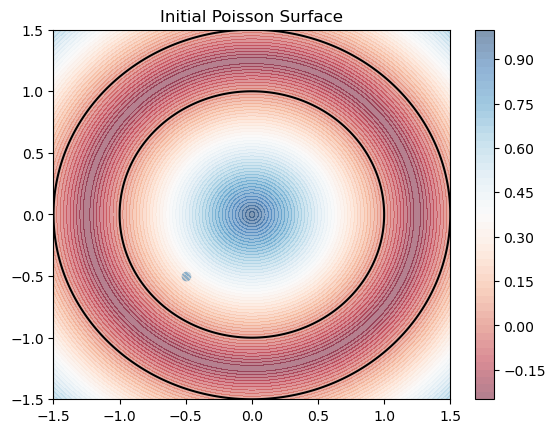

In [10]:
plt.scatter(surface_params['p'][:, 0], surface_params['p'][:, 1], cmap='viridis')
contouf = plt.contourf(X, Y, jax.vmap(to_opt_surface, in_axes=(None, 0))(to_opt_params, points).reshape(X.shape), levels=50, cmap='RdBu', alpha=0.5)
contour = plt.contour(X, Y, jax.vmap(to_opt_surface, in_axes=(None, 0))(to_opt_params, points).reshape(X.shape), levels=[to_opt_surface.level_set], colors='black')
plt.colorbar(contouf)
surf_points = jax.vmap(lambda key: sample_uniform_1sphere(key, jnp.float32))(jax.random.split(jax.random.PRNGKey(0), 1000)) * 0.95
surface_velocities = jax.vmap(to_opt_surface.normal_at, in_axes=(None, 0))(to_opt_params, surf_points)
surf_points2 = jnp.vstack((jnp.linspace(-1., 1., 100), jnp.ones((100,)))).T
surface_velocities2 = jax.vmap(to_opt_surface.normal_at, in_axes=(None, 0))(to_opt_params, surf_points2)
#plt.quiver(surf_points[:, 0], surf_points[:, 1], surface_velocities[:, 0], surface_velocities[:, 1], color='black', width=0.002)
#plt.quiver(surf_points2[:, 0], surf_points2[:, 1], surface_velocities2[:, 0], surface_velocities2[:, 1], color='red', width=0.002)
plt.title('Initial Poisson Surface')
plt.show()

In [11]:
def const_source_fn(x):
    return 4.0

def zero_boundary_condition(point: jnp.ndarray) -> jnp.ndarray:
    return 0.0

In [12]:
X, Y = mesh_2d(512, ((-1.5, 1.5), (-1.5, 1.5)))
opt_loop_points = jnp.stack([X, Y], axis=-1).reshape(-1, 2)
inside_reference_mask = jax.vmap(smily_sdf)(None, opt_loop_points) < 0

In [13]:
key = jax.random.PRNGKey(0)
N = 10000
ref_fn = smily_sdf
ref_fn = lambda p, x: jnp.maximum(-sphere_sdf({'center': jnp.array([0., 0.]), 'radius': 0.3}, x), outer_boundary(None, x))
reference_surface = sdfImplicit(fn=ref_fn, dim=2)

reference_solver = WoSIntegrator(
    empty_sphere_fn=reference_surface.empty_sphere, 
    boundary_condition_fn=zero_boundary_condition,
    source_term_fn=const_source_fn,
    dim=2,
    level_set=0.0,
    eps=1e-3,
    max_steps=1000,
    print_progress=False
)

inside_reference_mask = jax.vmap(reference_surface)(None, opt_loop_points) < 0
reference_estimate = reference_solver.integrate_batch(None, opt_loop_points[inside_reference_mask], rng_key=jax.random.PRNGKey(2), init_trust_region_size=jnp.inf, n_samples=512)
reference_estimate_full = jnp.zeros((opt_loop_points.shape[0], 1))
reference_estimate_full = reference_estimate_full.at[inside_reference_mask].set(reference_estimate.w)


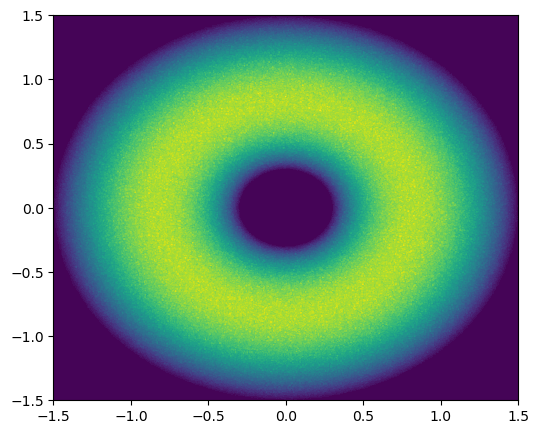

In [14]:
fig = plt.figure(figsize=(6, 5))
ax = fig.add_subplot(111)

contouf = ax.contourf(X, Y, reference_estimate_full.squeeze().reshape(X.shape), levels=50)
#ax.scatter(opt_loop_points[inside_reference_mask, 0], opt_loop_points[inside_reference_mask, 1])

In [15]:
def sgd_step(params, opt_state, grads, optimizer):
    updates, new_opt_state = optimizer.update(grads, opt_state)
    params_new = optax.apply_updates(params, updates)
    return params_new, new_opt_state

In [26]:
dif_integrator = DifferentialWoSIntegrator(
    empty_sphere_fn=to_opt_surface.empty_sphere, 
    boundary_condition_fn=zero_boundary_condition,
    source_term_fn=const_source_fn,
    Df=to_opt_surface.dirichlet_boundary_differential,
    V_n=to_opt_surface.normal_surface_velocity,
    normal_fn=to_opt_surface.normal_at,
    offset_l=0.01,
    dim=to_opt_surface.dim,
    level_set=to_opt_surface.level_set,
    eps=1e-3,
    max_steps=1000,
)

primary_integrator = WoSIntegrator(
    empty_sphere_fn=to_opt_surface.empty_sphere, 
    boundary_condition_fn=zero_boundary_condition,
    source_term_fn=const_source_fn,
    dim=to_opt_surface.dim,
    level_set=to_opt_surface.level_set,
    eps=1e-3,
    max_steps=1000,
    print_progress=False
)


#optimizer = optax.sgd(learning_rate=5.0)
#opt_state = optimizer.init(to_opt_params)

param_labels = {
    'center': 'train',
    'radius': 'train'  # Label this one 'fixed'
}
optimizer = optax.multi_transform(
    {
        'train': optax.sgd(learning_rate=0.3, momentum=0.9),
        'fixed': optax.set_to_zero()  # Explicitly zero out updates
    },
    param_labels
)
opt_state = optimizer.init(to_opt_params)

In [17]:
init_inside = jax.vmap(composed_field_fn, in_axes=(None, 0))(to_opt_params, opt_loop_points) < to_opt_surface.level_set

init_estimate = primary_integrator.integrate_batch(to_opt_params, opt_loop_points[init_inside], rng_key=jax.random.PRNGKey(2), init_trust_region_size=jnp.inf, n_samples=512)
init_estimate_full = jnp.zeros((opt_loop_points.shape[0], 1))
init_estimate_full = init_estimate_full.at[init_inside].set(init_estimate.w)

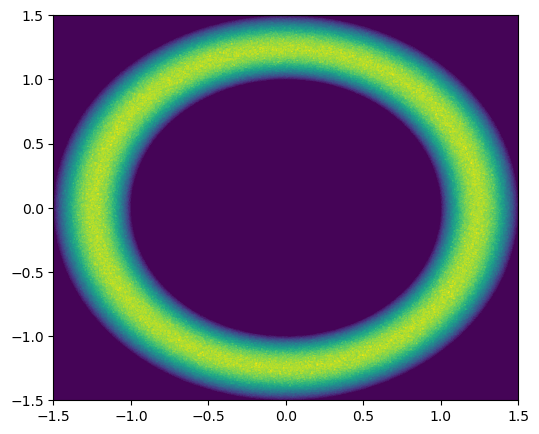

In [18]:
fig = plt.figure(figsize=(6, 5))
ax = fig.add_subplot(111)

contouf = ax.contourf(X, Y, init_estimate_full.squeeze().reshape(X.shape), levels=50)

In [19]:
def min_volume_loss(fn: Callable,
                    params,  
                    domain_samples: jnp.ndarray, 
                    domain_volume: float, 
                    min_volume: float, 
                    temperature: float = 20.0):
    """
    Penalizes the implicit surface ONLY if its volume drops below min_volume.
    Uses a volumetric approximation (soft Heaviside) to be differentiable.
    
    Args:
        params: Surface parameters.
        fn: Function signature fn(params, x) -> float.
        domain_samples: (N, dim) points sampled uniformly in the simulation box.
        domain_volume: Total volume of the bounding box where samples were drawn.
        min_volume: The minimum required volume for the shape.
        temperature: Controls sharpness of the boundary approximation. 
                     Higher = more accurate volume, sharper gradients.
                     Lower = smoother gradients, helps recovery from vanishing.
    
    Returns:
        Scalar loss. 0.0 if volume >= min_volume. Positive otherwise.
    """
    fn_values = jax.vmap(fn, in_axes=(None, 0))(params, domain_samples).squeeze()
    occupancy = jax.nn.sigmoid(-temperature * fn_values)
    current_volume = jnp.mean(occupancy) * domain_volume
    volume_deficit = jax.nn.relu(min_volume - current_volume)
    
    return jnp.square(volume_deficit)

In [20]:
min_volume_loss(to_opt_surface, to_opt_params, opt_loop_points, domain_volume=(X.max() - X.min()) * (Y.max() - Y.min()), min_volume=jnp.pi*(1.5**2 - 0.3**2) * 0.75)

Array(1.6271863, dtype=float32)

In [27]:
DOMAIN_AREA = (X.max() - X.min()) * (Y.max() - Y.min())
TARGET_MIN_VOLUME = jnp.pi * (1.5**2 - 0.3**2) * 0.75
EPSILON = 1e-3
LAMBDA_VOL = 0.01

u_solution_full = jnp.zeros((opt_loop_points.shape[0]))
du_dtheta_full = jax.tree.map(
    lambda x: jnp.zeros((opt_loop_points.shape[0], *x.shape)), 
    to_opt_params
)

def accumulate_gradients(vol_g, domain_g, surface_g):
    """Safely sums gradients, handling cases where surface_g might be None/Zero."""
    def sum_leaves(v, d, s):
        total = LAMBDA_VOL * v + d
        if s is not None:
            total += s
        return total
    return jax.tree.map(sum_leaves, vol_g, domain_g, surface_g)

# --- Training Loop ---
for i in range(25):
    # --- Phase A: Geometry & Masks ---
    # Evaluate fn and gradients
    sdf_val = jax.vmap(to_opt_surface, in_axes=(None, 0))(to_opt_params, opt_loop_points)
    sdf_grad = jax.vmap(to_opt_surface.spatial_derivative, in_axes=(None, 0))(to_opt_params, opt_loop_points)
    normal_velocity = jax.vmap(to_opt_surface.normal_surface_velocity, in_axes=(None, 0))(to_opt_params, opt_loop_points)
    
    # Define topological masks
    omega_mask = sdf_val < to_opt_surface.level_set # Domain Omega
    intersection_mask = jnp.logical_and(inside_reference_mask, omega_mask) # Intersection with reference domain
    boundary_mask = jnp.logical_and(inside_reference_mask, jnp.abs(sdf_val - to_opt_surface.level_set) < EPSILON) # dOmega

    # metrics
    N_omega = omega_mask.sum()
    N_boundary = boundary_mask.sum()
    
    vol_approx_intersection = DOMAIN_AREA * intersection_mask.mean()
    vol_approx_omega = DOMAIN_AREA * omega_mask.mean()
    vol_approx_boundary = DOMAIN_AREA * boundary_mask.mean()

    print(f"Iter {i}: Omega pts: {N_omega} | Boundary pts: {N_boundary}")

    # --- Phase B: Volume Regularization Gradient ---
    grad_volume = jax.grad(min_volume_loss, argnums=1)(
        to_opt_surface, 
        to_opt_params, 
        opt_loop_points, 
        domain_volume=DOMAIN_AREA, 
        min_volume=TARGET_MIN_VOLUME
    )

    # --- Phase C: Physics (Monte Carlo Integration) ---
    if N_omega == 0:
        print(f"  -> Skipping step: No points inside domain.")
        break 

    # Solve PDE (Value and Sensitivity) only at required points
    active_points = opt_loop_points[omega_mask]
    rng_key = jax.random.PRNGKey(i) # Vary key per iteration
    
    u_estimate = primary_integrator.integrate_batch(
        to_opt_params, active_points, rng_key=rng_key, 
        init_trust_region_size=jnp.inf, n_samples=1, steps_between_refill=100
    )
    
    du_estimate = dif_integrator.integrate_batch(
        to_opt_params, active_points, rng_key=rng_key, 
        init_trust_region_size=jnp.inf, n_samples=1, steps_between_refill=100
    )

    # Update full solution arrays (optional, mostly for debugging/metrics)
    u_solution_full = u_solution_full.at[omega_mask].set(u_estimate.w.squeeze())
    du_dtheta_full = jax.tree.map(
        lambda full, new: full.at[omega_mask].set(new), 
        du_dtheta_full, 
        du_estimate.w
    )

    # Calculate Current Loss
    targets = reference_estimate_full.squeeze()[omega_mask]
    preds = u_solution_full[omega_mask]
    mse = l2_loss(preds, targets)
    total_loss = jnp.sum(mse) * vol_approx_intersection / N_omega
    print(f"  -> Normalized Loss: {total_loss / vol_approx_omega:.6f}")

    # --- Phase D: Reynolds Transport Gradients ---
    
    # 1. Domain Integral Gradient (Fixed Domain contribution)
    grad_domain = volume_integral_loss_grad(
        dL_dparams_field=dL2_du,
        mask=omega_mask,
        volume=vol_approx_intersection,
        normalization_factor=vol_approx_omega,
        solution_u=u_solution_full,
        solution_target=reference_estimate_full.squeeze(),
        del_solution_del_theta=du_dtheta_full, # Pass the sparse/masked dict if possible to save mem
    )

    # 2. Surface Integral Gradient (Moving Boundary contribution)
    grad_surface = None
    if N_boundary > 0:
        grad_surface = surface_integral_loss_grad_normalized(
            loss_fn=l2_loss,
            epsilon_volume=vol_approx_boundary,
            epsilon=EPSILON,
            normalization_factor=vol_approx_omega,
            unnormalized_energy=total_loss,
            solution_u=u_solution_full,
            solution_target=reference_estimate_full.squeeze(),
            normal_velocity_field=normal_velocity,
            mask=boundary_mask,
        )

    # --- Phase E: Update ---
    final_grads = accumulate_weighted_trees((grad_volume, grad_domain, grad_surface), (LAMBDA_VOL, 1.0, 1.0))
    
    # Assuming optimizer handles the update
    to_opt_params, opt_state = sgd_step(to_opt_params, opt_state, final_grads, optimizer)
    print(f"  -> Updated radius: {to_opt_params['radius']}")

Iter 0: Omega pts: 199693 | Boundary pts: 168
  -> Normalized Loss: 0.217854
  -> Updated radius: 0.26391667127609253
Iter 1: Omega pts: 198660 | Boundary pts: 168
  -> Normalized Loss: 0.198953
  -> Updated radius: 0.307701051235199
Iter 2: Omega pts: 196378 | Boundary pts: 275
  -> Normalized Loss: 0.170036
  -> Updated radius: 0.3345071077346802
Iter 3: Omega pts: 194811 | Boundary pts: 287
  -> Normalized Loss: 0.154481
  -> Updated radius: 0.31940069794654846
Iter 4: Omega pts: 195720 | Boundary pts: 278
  -> Normalized Loss: 0.164027
  -> Updated radius: 0.28887006640434265
Iter 5: Omega pts: 197407 | Boundary pts: 204
  -> Normalized Loss: 0.184892
  -> Updated radius: 0.2734796404838562
Iter 6: Omega pts: 198197 | Boundary pts: 168
  -> Normalized Loss: 0.194675
  -> Updated radius: 0.26893654465675354
Iter 7: Omega pts: 198419 | Boundary pts: 168
  -> Normalized Loss: 0.197413
  -> Updated radius: 0.27597567439079285
Iter 8: Omega pts: 198069 | Boundary pts: 168
  -> Normalize

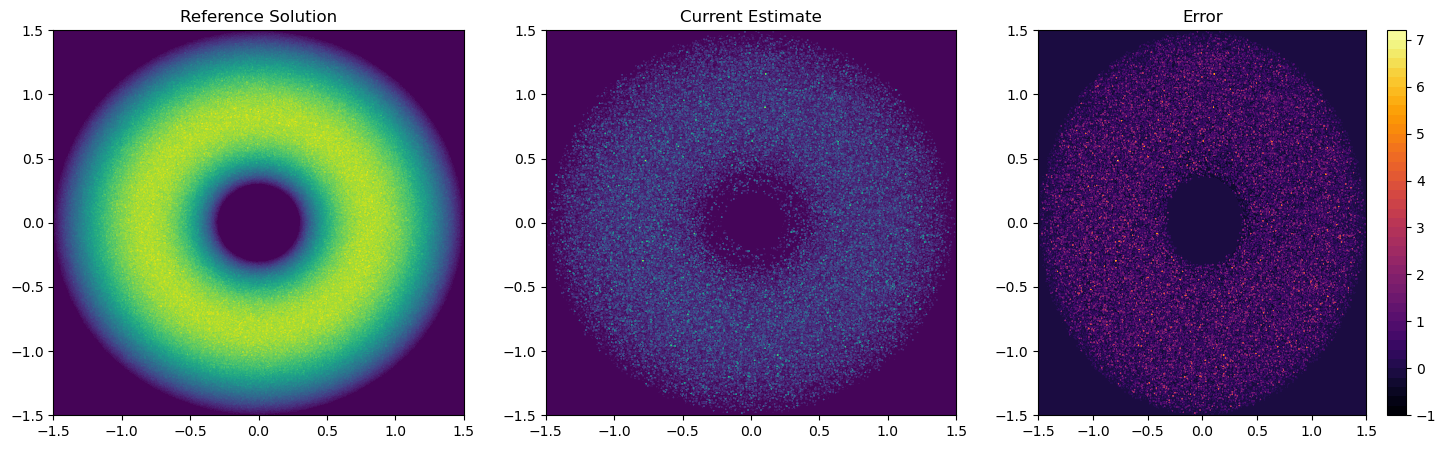

In [24]:
fig = plt.figure(figsize=(18, 5))
ax1 = fig.add_subplot(131)
contouf1 = ax1.contourf(X, Y, reference_estimate_full.squeeze().reshape(X.shape), levels=50)
ax1.set_title('Reference Solution')
ax2 = fig.add_subplot(132)
contouf2 = ax2.contourf(X, Y, u_solution_full.squeeze().reshape(X.shape), levels=50)
ax2.set_title('Current Estimate')
ax3 = fig.add_subplot(133)
error = jnp.zeros((opt_loop_points.shape[0]))
error = error.at[intersection_mask].set((u_solution_full.squeeze() - reference_estimate_full.squeeze())[intersection_mask])
contouf3 = ax3.contourf(X, Y, error.reshape(X.shape), levels=50, cmap='inferno')
plt.colorbar(contouf3, ax=ax3)
ax3.set_title('Error')
plt.show()

### Annuluas analytical test

In [ ]:
def solution_analytical(R_min, R_max, const_source, x):
    r = jnp.linalg.norm(x)
    result = const_source(x)/4.0 * (R_max**2 - r**2 - jnp.log(R_max/r) * (R_max**2 - R_min**2)/jnp.log(R_max/R_min))
    return jnp.where(jnp.logical_and(r > R_min, r < R_max), result, 0.0)

def solution_Rmin_deriv(R_min, R_max, const_source, x):
    r = jnp.linalg.norm(x)
    log_term = jnp.log(R_max/R_min)
    result = const_source(x)/4.0 * jnp.log(R_max/r) * (2*R_min/log_term - (R_max**2 - R_min**2)/(R_min * log_term**2))
    return jnp.where(jnp.logical_and(r > R_min, r < R_max), result, 0.0)

def surface_integral(R_min_opt, R_min_target, R_max, const_source):
    int_term = 2 * jnp.pi * R_min_opt
    sol_at_Rmin_opt = solution_analytical(R_min_opt, R_max, const_source, jnp.array([R_min_opt, 0.0]))
    sol_at_Rmin_target = solution_analytical(R_min_target, R_max, const_source, jnp.array([R_min_opt, 0.0]))
    Vn = -1.
    return int_term * l2_loss(sol_at_Rmin_opt, sol_at_Rmin_target) * Vn

def surface_integral_normalized(R_min_opt, R_min_target, R_max, const_source):
    sol_at_Rmin_opt = solution_analytical(R_min_opt, R_max, const_source, jnp.array([R_min_opt, 0.0]))
    sol_at_Rmin_target = solution_analytical(R_min_target, R_max, const_source, jnp.array([R_min_opt, 0.0]))
    r_vals = jnp.linspace(R_min_opt, R_max, 1000)
    loss_vals = jax.vmap(lambda r: solution_analytical(R_min_opt, R_max, const_source, jnp.array([r, 0.0])))(r_vals) - jax.vmap(lambda r: solution_analytical(R_min_target, R_max, const_source, jnp.array([r, 0.0])))(r_vals)
    loss_total = jnp.trapezoid(0.5*loss_vals**2*r_vals, r_vals) * 2 * jnp.pi
    Vn = -1.
    vol_annulus = jnp.pi * (R_max**2 - R_min_opt**2)
    surface = 2 * jnp.pi * R_min_opt
    J_avg = loss_total / vol_annulus
    return surface * (l2_loss(sol_at_Rmin_opt, sol_at_Rmin_target) - J_avg) * Vn / vol_annulus, loss_total

def volume_integral(R_min_opt, R_min_target, R_max, const_source):
    r_vals = jnp.linspace(R_min_opt, R_max, 1000)
    solution_opt = jax.vmap(lambda r: solution_analytical(R_min_opt, R_max, const_source, jnp.array([r, 0.0])))(r_vals)
    solution_target = jax.vmap(lambda r: solution_analytical(R_min_target, R_max, const_source, jnp.array([r, 0.0])))(r_vals)
    solution_dot = jax.vmap(lambda r: solution_Rmin_deriv(R_min_opt, R_max, const_source, jnp.array([r, 0.0])))(r_vals)
    integrand = dL2_du(solution_opt, solution_target) * solution_dot * r_vals

    vol_annulus = jnp.pi * (R_max**2 - R_min_opt**2)
    
    return jnp.trapezoid(integrand, r_vals) * 2 * jnp.pi / vol_annulus

In [ ]:
R_min_opt = 1.0
R_min_target = 0.3
R_max = 1.5
const_source = const_source_fn

r_vals = jnp.linspace(R_min_opt, R_max, 1000)
sol_opt = jax.vmap(lambda r: solution_analytical(R_min_opt, R_max, const_source, jnp.array([r, 0.0])))(r_vals)
sol_target = jax.vmap(lambda r: solution_analytical(R_min_target, R_max, const_source, jnp.array([r, 0.0])))(r_vals)
loss_vals = l2_loss(sol_opt, sol_target)
loss_total = jnp.trapezoid(loss_vals*r_vals, r_vals) * 2 * jnp.pi
loss_total

Array(0.2624381, dtype=float32)

In [30]:
surface_integral(jnp.array(1.0), jnp.array(0.3), jnp.array(1.5), const_source_fn)

Array(-1.5651376, dtype=float32)

In [38]:
surface_integral_normalized(jnp.array(1.0), jnp.array(0.3), jnp.array(1.5), const_source_fn)

(Array(-0.29163212, dtype=float32), Array(0.2624381, dtype=float32))

In [28]:
volume_integral(jnp.array(1.0), jnp.array(0.3), jnp.array(1.5), const_source_fn)

Array(0.20475148, dtype=float32)

In [49]:
to_opt_params['radius'] = jnp.array(1.0)

In [50]:
to_opt_surface.normal_surface_velocity(to_opt_params, jnp.array([0.5, 0.0]))

{'center': Array([-0.38810667,  0.9216145 ], dtype=float32),
 'radius': Array(-1.0000001, dtype=float32)}

In [42]:
def surface_integral_normalized2(R_min_opt, R_min_target, R_max, const_source):
    # 1. Geometry: Calculate the Volume (Area) of the actual domain (Annulus)
    # ERROR FIX: Was calculating area of the hole
    vol_annulus = jnp.pi * (R_max**2 - R_min_opt**2)
    
    # 2. Total Energy Calculation (Volume Integral)
    # This part was mostly correct, just ensuring trapezoid uses the right axis
    r_vals = jnp.linspace(R_min_opt, R_max, 1000)
    sol_opt = jax.vmap(lambda r: solution_analytical(R_min_opt, R_max, const_source, jnp.array([r, 0.0])))(r_vals)
    sol_target = jax.vmap(lambda r: solution_analytical(R_min_target, R_max, const_source, jnp.array([r, 0.0])))(r_vals)
    
    loss_density_vals = 0.5 * (sol_opt - sol_target)**2
    # Integrate density * r * dr * 2pi
    loss_total = jnp.trapezoid(loss_density_vals * r_vals, r_vals) * 2 * jnp.pi
    
    # 3. Calculate Average Loss Density (J_avg)
    # ERROR FIX: Needed to divide Total Energy by Volume
    J_avg = loss_total / vol_annulus

    # 4. Local Loss at the Boundary
    sol_at_boundary = solution_analytical(R_min_opt, R_max, const_source, jnp.array([R_min_opt, 0.0]))
    sol_target_at_boundary = solution_analytical(R_min_target, R_max, const_source, jnp.array([R_min_opt, 0.0]))
    L_local = l2_loss(sol_at_boundary, sol_target_at_boundary)
    
    # 5. Surface Integral (Circumference * (Local - Avg) * Vn)
    circumference = 2 * jnp.pi * R_min_opt
    Vn = -1.0
    
    # 6. Final Quotient Rule Application
    # Formula: (1/Vol) * Integral
    return (1.0 / vol_annulus) * circumference * (L_local - J_avg) * Vn

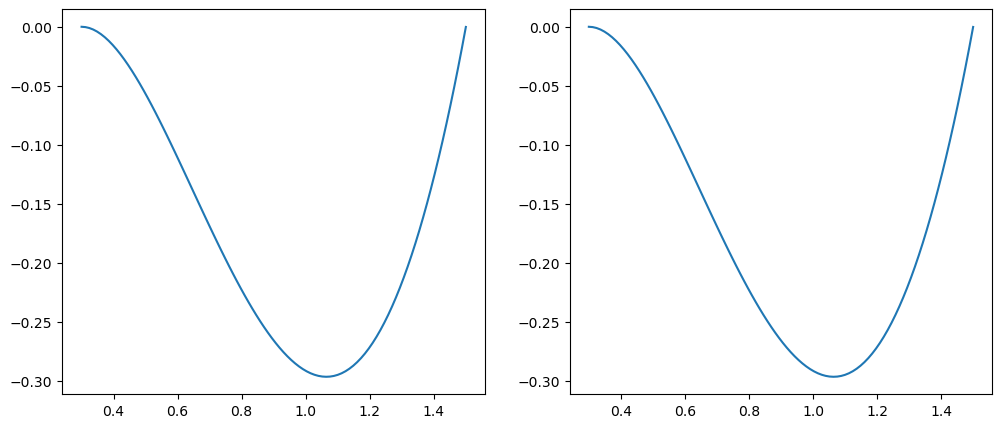

In [43]:
R_to_opt_vals = jnp.linspace(0.3001, 1.4999, 100)
surf_grad_vals = jax.vmap(lambda R_opt: surface_integral_normalized(R_opt, 0.3, 1.5, const_source_fn))(R_to_opt_vals)
surf_grad_vals_normalized = jax.vmap(lambda R_opt: surface_integral_normalized2(R_opt, 0.3, 1.5, const_source_fn))(R_to_opt_vals)

fig = plt.figure(figsize=(12, 5))
ax1 = fig.add_subplot(121)
ax1.plot(R_to_opt_vals, surf_grad_vals)

ax2 = fig.add_subplot(122)
ax2.plot(R_to_opt_vals, surf_grad_vals_normalized)
plt.show()

In [183]:
volume_integral(jnp.array(1.0), jnp.array(0.99), jnp.array(1.5), const_source_fn)

Array(0.01232091, dtype=float32)

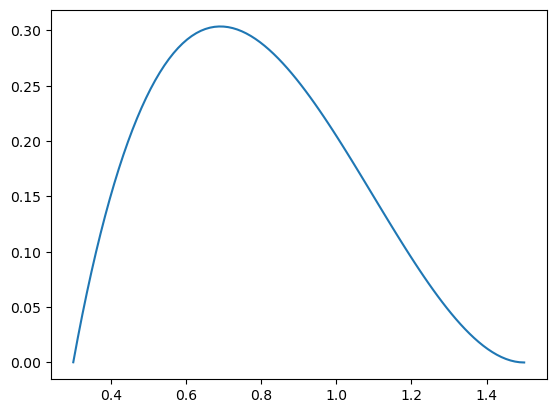

In [45]:
R_to_opt_vals = jnp.linspace(0.3001, 1.4999, 100)
vol_grad_vals = jax.vmap(lambda R_opt: volume_integral(R_opt, 0.3, 1.5, const_source_fn))(R_to_opt_vals)
plt.plot(R_to_opt_vals, vol_grad_vals)

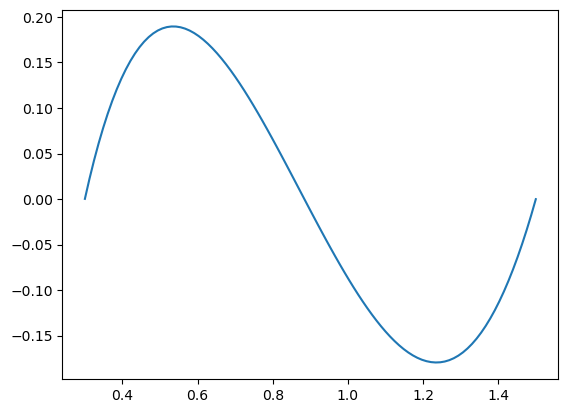

In [46]:
plt.plot(R_to_opt_vals, surf_grad_vals_normalized+vol_grad_vals)

In [175]:
add_surface_grad_fn({'center': jnp.array([-0., -0.]), 'radius': jnp.array(0.0)}, 
                    {'center': jnp.array([-0., -0.]), 'radius': jnp.array(1.0)}, 
                    jnp.abs(jax.vmap(composed_field_fn, in_axes=(None, 0))(to_opt_params, opt_loop_points) - to_opt_surface.level_set) < 1e-3)

{'center': Array([ 0.00546464, -0.0010561 ], dtype=float32), 'radius': Array(-1.523743, dtype=float32)}


{'center': Array([ 0.00546464, -0.0010561 ], dtype=float32),
 'radius': Array(-1.523743, dtype=float32)}

In [173]:
add_volume_integral_grad_fn({'center': jnp.array([-0., -0.]), 'radius': jnp.array(0.0)},
                            {'center': jnp.array([-0., -0.]), 'radius': jnp.array(1.0)},
                            jax.vmap(composed_field_fn, in_axes=(None, 0))(to_opt_params, opt_loop_points) < to_opt_surface.level_set
)

{'center': Array([ 0.00114084, -0.00207945], dtype=float32), 'radius': Array(0.7813377, dtype=float32)}


({'center': Array([ 0.00114084, -0.00207945], dtype=float32),
  'radius': Array(0.7813377, dtype=float32)},
 Array([0.        , 0.        , 0.00110935, ..., 0.00017118, 0.        ,
        0.        ], dtype=float32))

In [130]:
R_min = jnp.array(1.0)
R_max = jnp.array(1.5)
anal_sol = jax.vmap(solution_analytical, in_axes=(None, None, None, 0))(R_min, R_max, const_source_fn, opt_loop_points)
anal_sol_deriv = jax.vmap(solution_Rmin_deriv, in_axes=(None, None, None, 0))(R_min, R_max, const_source_fn, opt_loop_points)

In [141]:
to_opt_params['radius'] = R_min

init_inside = jax.vmap(composed_field_fn, in_axes=(None, 0))(to_opt_params, opt_loop_points) < to_opt_surface.level_set

init_estimate = primary_integrator.integrate_batch(to_opt_params, opt_loop_points[init_inside], rng_key=jax.random.PRNGKey(30), init_trust_region_size=jnp.inf, n_samples=10024)
init_estimate_full = jnp.zeros((opt_loop_points.shape[0], 1))
init_estimate_full = init_estimate_full.at[init_inside].set(init_estimate.w)

In [147]:
init_deriv_estimate = dif_integrator.integrate_batch(to_opt_params, opt_loop_points[init_inside], rng_key=jax.random.PRNGKey(30), init_trust_region_size=jnp.inf, n_samples=10024)
init_deriv_estimate_full = jnp.zeros((opt_loop_points.shape[0]))
init_deriv_estimate_full = init_deriv_estimate_full.at[init_inside].set(init_deriv_estimate.w['radius'])

In [144]:
to_opt_params

{'center': Array([-0., -0.], dtype=float32),
 'radius': Array(1., dtype=float32, weak_type=True)}

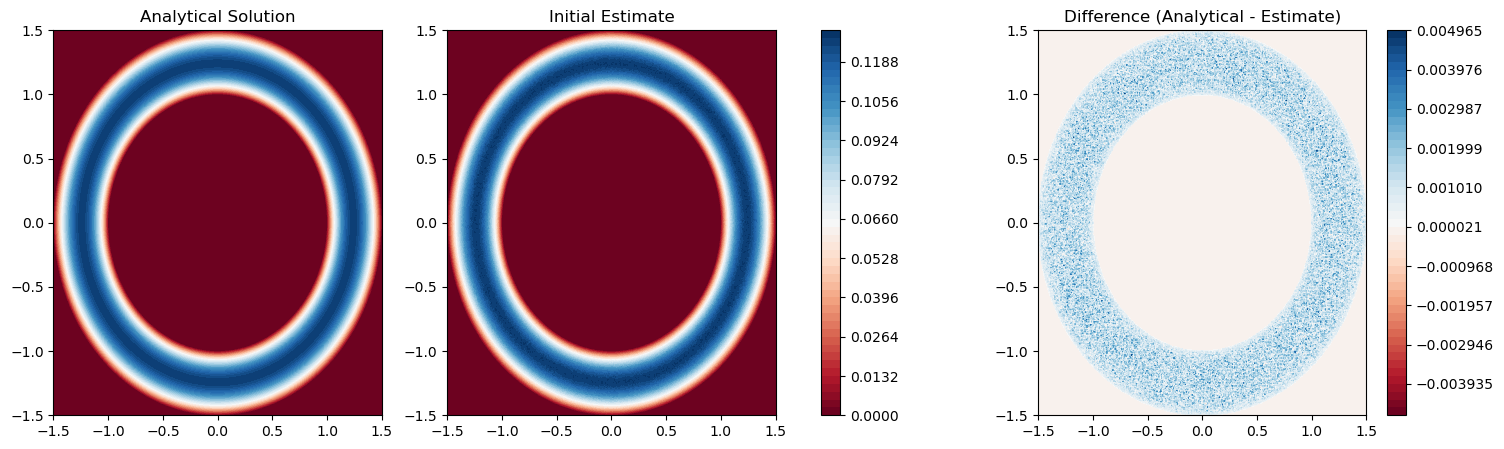

In [142]:
vmin = min(anal_sol.min(), init_estimate_full.min())
vmax = max(anal_sol.max(), init_estimate_full.max())
# Create 50 consistent levels for both plots
levels = np.linspace(vmin, vmax, 50)


fig = plt.figure(figsize=(18, 5))
ax = fig.add_subplot(131)
contouf = ax.contourf(X, Y, anal_sol.reshape(X.shape), levels=levels, cmap='RdBu')
ax.set_title('Analytical Solution')

init_estimate_full = jnp.zeros((opt_loop_points.shape[0], 1))
init_estimate_full = init_estimate_full.at[init_inside].set(init_estimate.w)
ax2 = fig.add_subplot(132)
contouf2 = ax2.contourf(X, Y, init_estimate_full.squeeze().reshape(X.shape), levels=levels, cmap='RdBu')
ax2.set_title('Initial Estimate')
fig.colorbar(contouf, ax=[ax, ax2])

difference = (anal_sol - init_estimate_full.squeeze()).reshape(X.shape)
vmin_diff = difference.min()
vmax_diff = difference.max()
levels_diff = np.linspace(vmin_diff, vmax_diff, 50)
ax3 = fig.add_subplot(133)
contouf3 = ax3.contourf(X, Y, difference, levels=levels_diff, cmap='RdBu')
ax3.set_title('Difference (Analytical - Estimate)')
fig.colorbar(contouf3, ax=ax3)
plt.show()

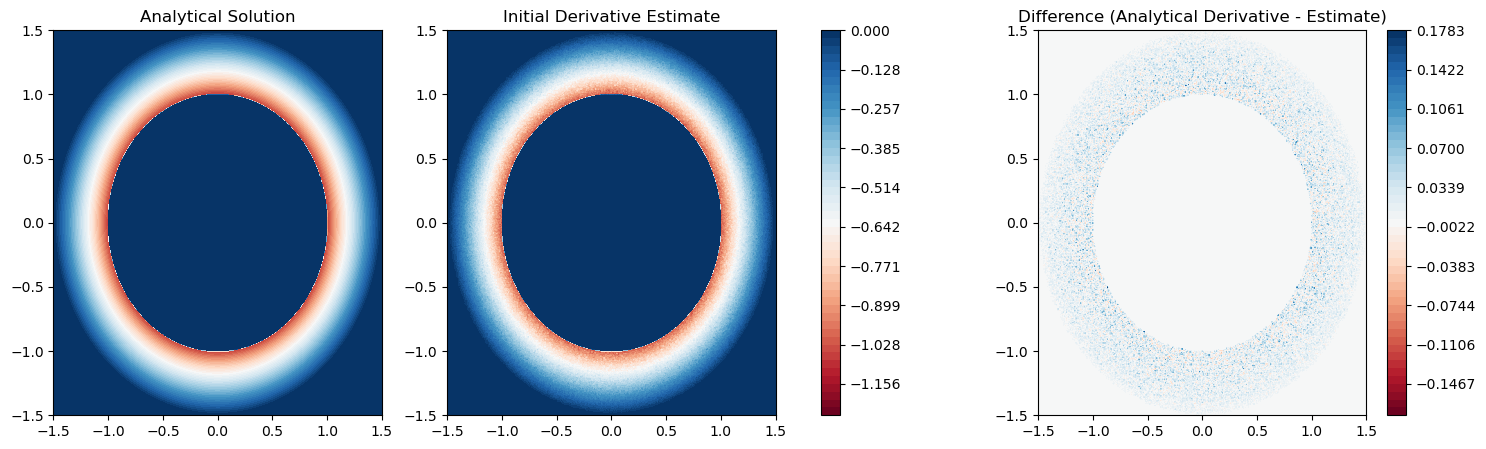

In [148]:
vmin = min(anal_sol_deriv.min(), init_deriv_estimate_full.min())
vmax = max(anal_sol_deriv.max(), init_deriv_estimate_full.max())
# Create 50 consistent levels for both plots
levels = np.linspace(vmin, vmax, 50)


fig = plt.figure(figsize=(18, 5))
ax = fig.add_subplot(131)
contouf = ax.contourf(X, Y, anal_sol_deriv.reshape(X.shape), levels=levels, cmap='RdBu')
ax.set_title('Analytical Solution')

ax2 = fig.add_subplot(132)
contouf2 = ax2.contourf(X, Y, init_deriv_estimate_full.reshape(X.shape), levels=levels, cmap='RdBu')
ax2.set_title('Initial Derivative Estimate')
fig.colorbar(contouf, ax=[ax, ax2])

difference = (anal_sol_deriv - init_deriv_estimate_full).reshape(X.shape)
vmin_diff = difference.min()
vmax_diff = difference.max()
levels_diff = np.linspace(vmin_diff, vmax_diff, 50)
ax3 = fig.add_subplot(133)
contouf3 = ax3.contourf(X, Y, difference, levels=levels_diff, cmap='RdBu')
ax3.set_title('Difference (Analytical Derivative - Estimate)')
fig.colorbar(contouf3, ax=ax3)
plt.show()